<a href="https://colab.research.google.com/github/ichrak2671/Projet_DataScience_Maroc/blob/main/Copie_de_Copie_de_Copie_de_Template_Projet_DataScience_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Template étudiant — Data Science et commerce international

**Binôme :** ichrak driouich / Zine El Abdine Imane

**Projet :** Projet 01 - Prévision des exportations marocaines par produit  
**Date :** [05/11/2026]

**Important :** notebook volontairement incomplet. Ne pas inventer de données. Garder un journal des sources et paramètres de requêtes.

In [ ]:
# Bibliothèques principales
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit, train_test_split
GRAINE_ALEATOIRE = 42
print('Versions :', np.__version__, pd.__version__)

Versions : 2.4.6 2.2.3


## 1. Problématique et hypothèses

**À faire :** Définir la décision commerciale, l’unité d’analyse, la période et la variable cible.

**Réponse du binôme :**
- **Décision commerciale :** anticiper la valeur des exportations marocaines de légumes (chapitre HS 07) pour appuyer la planification de la filière, la logistique et le ciblage des marchés.
- **Unité d'analyse :** valeur annuelle des exportations du Maroc (déclarant 504) vers le monde (partenaire 0), chapitre HS2 07.
- **Période :** 2010–2024 (la couverture effective est contrôlée dans la section 3).
- **Variable cible :** valeur exportée l'année t+1 (en milliards USD), prédite avec les informations connues à l'année t.

## 2. Accès aux données

**À faire :** Coller l’URL officielle et l’URL du fichier/API documentée. Vérifier la licence, quotas, clés et période.

**Réponse du binôme :**
- **Source officielle :** UN Comtrade (Nations Unies).
- **Documentation :** https://uncomtrade.org/docs/un-comtrade-api/
- **Point d'accès :** https://comtradeapi.un.org/public/v1/preview/C/A/HS
- **Paramètres :** reporterCode=504 (Maroc), partnerCode=0 (Monde), cmdCode=07, flowCode=X (export), period=2010…2024 (une requête par année).
- **Licence et quotas :** API publique « preview » sans clé, limitée à 500 lignes par requête et à des limites de fréquence ; un délai est donc inséré entre les requêtes et un journal des requêtes est conservé.

In [ ]:
url_api = "https://comtradeapi.un.org/public/v1/preview/C/A/HS"
parametres_base = {"reporterCode": 504, "partnerCode": 0, "cmdCode": "07", "flowCode": "X"}
print("Point d'accès :", url_api)
print("Paramètres :", parametres_base, "| period = 2010…2024 (une requête par année)")

Point d'accès : https://comtradeapi.un.org/public/v1/preview/C/A/HS
Paramètres : {'reporterCode': 504, 'partnerCode': 0, 'cmdCode': '07', 'flowCode': 'X'} | period = 2010…2024 (une requête par année)


## 3. Chargement

**À faire :** Charger les données en DataFrame, afficher dimensions et colonnes ; identifier les erreurs HTTP et cas de données vides.

**Réponse du binôme :**
- **Dimensions :** à lire dans la sortie de la cellule ci-dessous (nombre de lignes/colonnes et années réellement récupérées). La couverture effective peut être plus courte que 2010–2024.
- **Gestion des erreurs :** chaque requête est journalisée (code HTTP) ; en cas de HTTP ≠ 200 (ex. 429 quota) ou de réponse vide, l'année est signalée dans le journal. Aucune donnée n'est inventée ni imputée.

In [ ]:
import pandas as pd

# 1. Filtrer les réponses de la liste 'morceaux' pour ne conserver que les DataFrames non vides
# (Ceci permet d'éliminer les erreurs 429 de quota sans générer d'avertissement)
morceaux_valides = [df for df in morceaux if isinstance(df, pd.DataFrame) and not df.empty]

# 2. Concaténation sécurisée des données
if morceaux_valides:
    donnees = pd.concat(morceaux_valides, ignore_index=True)
    print(f"✅ Concaténation réussie : {donnees.shape[0]} lignes et {donnees.shape[1]} colonnes chargées.")
else:
    print("⚠️ Attention : Aucun morceau valide n'a été récupéré.")

# 3. Aperçu des dimensions et vérification des premières lignes
print(f"Dimensions du DataFrame final : {donnees.shape}")
donnees.head()

✅ Concaténation réussie : 10 lignes et 47 colonnes chargées.
Dimensions du DataFrame final : (10, 47)


/tmp/ipykernel_923/1331870205.py:9: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  donnees = pd.concat(morceaux_valides, ignore_index=True)


,typeCode,freqCode,refPeriodId,refYear,refMonth,period,reporterCode,reporterISO,reporterDesc,flowCode,...,netWgt,isNetWgtEstimated,grossWgt,isGrossWgtEstimated,cifvalue,fobvalue,primaryValue,legacyEstimationFlag,isReported,isAggregate
0,C,A,20100101,2010,52,2010,504,None,None,X,...,NaN,False,NaN,False,NaN,6.012525e+08,6.012525e+08,0,True,False
1,C,A,20120101,2012,52,2012,504,None,None,X,...,NaN,False,NaN,False,NaN,6.721975e+08,6.721975e+08,0,True,False
2,C,A,20140101,2014,52,2014,504,None,None,X,...,NaN,False,NaN,False,NaN,8.649811e+08,8.649811e+08,0,True,False
3,C,A,20160101,2016,52,2016,504,None,None,X,...,NaN,False,NaN,False,NaN,9.025643e+08,9.025643e+08,0,True,False
4,C,A,20180101,2018,52,2018,504,None,None,X,...,0.0,True,0.0,False,NaN,1.287429e+09,1.287429e+09,4,False,True


## 4. Dictionnaire de variables

**À faire :** Créer un tableau : variable, type, unité, description, source.

**Réponse du binôme :**

| Variable | Type | Unité | Description | Source |
| :--- | :--- | :--- | :--- | :--- |
| `period` | Entier (`int`) | Année | Année d'observation du flux commercial | UN Comtrade |
| `reporterCode` | Entier (`int`) | Code M49 (Comtrade) | Pays déclarant (504 = Maroc) | UN Comtrade |
| `partnerCode` | Entier (`int`) | Code M49 (Comtrade) | Pays partenaire (0 = Monde) | UN Comtrade |
| `cmdCode` | Chaîne (`str`) | Code HS | Chapitre de la nomenclature douanière (07 = légumes) | UN Comtrade |
| `flowCode` | Chaîne (`str`) | Code flux | Type de flux (X = exportation) | UN Comtrade |
| `primaryValue` | Flottant (`float`) | USD courants | Valeur commerciale annuelle des exportations | UN Comtrade |
| `valeur_mds` | Flottant (`float`) | Milliards USD | `primaryValue / 1e9`, variable créée pour l'analyse | Calculée |

## 5. Qualité et nettoyage

**À faire :** Tracer manquants, doublons, variables incohérentes ; justifier chaque transformation.

**Réponse du binôme :**
- **Valeurs manquantes et doublons :** contrôle des valeurs nulles sur `period` et `primaryValue`, comptage des doublons exacts, vérification qu'il n'y a qu'une seule ligne par année pour (Maroc, Monde, HS 07, export).
- **Transformations :** conversion de `period` et `primaryValue` en numérique, filtre `flowCode == 'X'`, tri chronologique, création de `valeur_mds` (valeur en milliards USD).
- **Principe :** aucune imputation ni donnée de substitution. Si une année est absente de l'API, elle reste absente et la couverture réelle est indiquée.

In [ ]:
from sklearn.model_selection import train_test_split

# 1. Sélection uniquement de la colonne 'refYear' comme variable explicative (X)
# et de la valeur des exportations comme cible (y)
X = donnees[['refYear']]

# Utiliser valeur_mds si créée, sinon primaryValue
if 'valeur_mds' in donnees.columns:
    y = donnees['valeur_mds']
else:
    y = donnees['primaryValue']

# 2. Découpage temporel (3 observations en test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, shuffle=False
)

print("✅ Découpage effectué avec succès :")
print(f"   - Jeu d'entraînement (Train) : {len(X_train)} lignes")
print(f"   - Jeu de test (Test)         : {len(X_test)} lignes")

✅ Découpage effectué avec succès :
   - Jeu d'entraînement (Train) : 7 lignes
   - Jeu de test (Test)         : 3 lignes


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, KFold

# 1. Modèle de base
modele_base = RandomForestRegressor(random_state=42)

# 2. Grille d'hyperparamètres simple
param_grid = {'n_estimators': [5, 10, 20], 'max_depth': [2, 3]}

# 3. Validation croisée adaptée aux petits jeux de données (k=3)
cv_strategy = KFold(n_splits=3, shuffle=False)

# 4. Configuration et entraînement de la recherche par grille
grid_search = GridSearchCV(
    estimator=modele_base,
    param_grid=param_grid,
    cv=cv_strategy,
    scoring='neg_mean_absolute_error',
    return_train_score=True,
)

# Entraînement
grid_search.fit(X_train, y_train)

# Extraction du meilleur modèle
best_model = grid_search.best_estimator_
print("✅ Recherche d'hyperparamètres terminée sans erreur !")
print("Meilleurs hyperparamètres retenus :", grid_search.best_params_)

✅ Recherche d'hyperparamètres terminée sans erreur !
Meilleurs hyperparamètres retenus : {'max_depth': 2, 'n_estimators': 20}


In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Calcul des prédictions sur le jeu de test
y_pred = best_model.predict(X_test)

# 2. Calcul des métriques de performance
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

# 3. Affichage des résultats
print("==========================================")
print("     ÉVALUATION FINALE DU MODÈLE          ")
print("==========================================")
print(f"MAE  (Erreur Absolue Moyenne) : {mae:.4f}")
print(f"RMSE (Racine Carrée de l'MSE) : {rmse:.4f}")
print(f"R²   (Coefficient de Déterm.) : {r2:.4f}")
print("==========================================")

     ÉVALUATION FINALE DU MODÈLE          
MAE  (Erreur Absolue Moyenne) : 402390650.7702
RMSE (Racine Carrée de l'MSE) : 485899613.3913
R²   (Coefficient de Déterm.) : -2.1828


## 6. Analyse exploratoire

**À faire :** Produire cinq figures numérotées et une interprétation économique pour chacune.

**Réponse du binôme :** 1. **Figure 1 (Évolution temporelle) :** Analyse de la tendance générale des exportations marocaines sur la période 2010-2024.
2. **Figure 2 (Taux de croissance annuel) :** Identification des années de forte expansion et des ralentissements économiques.
3. **Figure 3 (Distribution des valeurs) :** Histogramme et boîte à moustaches montrant la dispersion et la présence d'outliers.
4. **Figure 4 (Moyenne mobile 3 ans) :** Lissage de la série temporelle pour isoler la tendance de fond des variations de court terme.
5. **Figure 5 (Autocorrélation / Retards t-1) :** Évaluation de la dépendance entre la valeur commerciale à t et t-1 pour justifier le choix des modèles prédictifs.

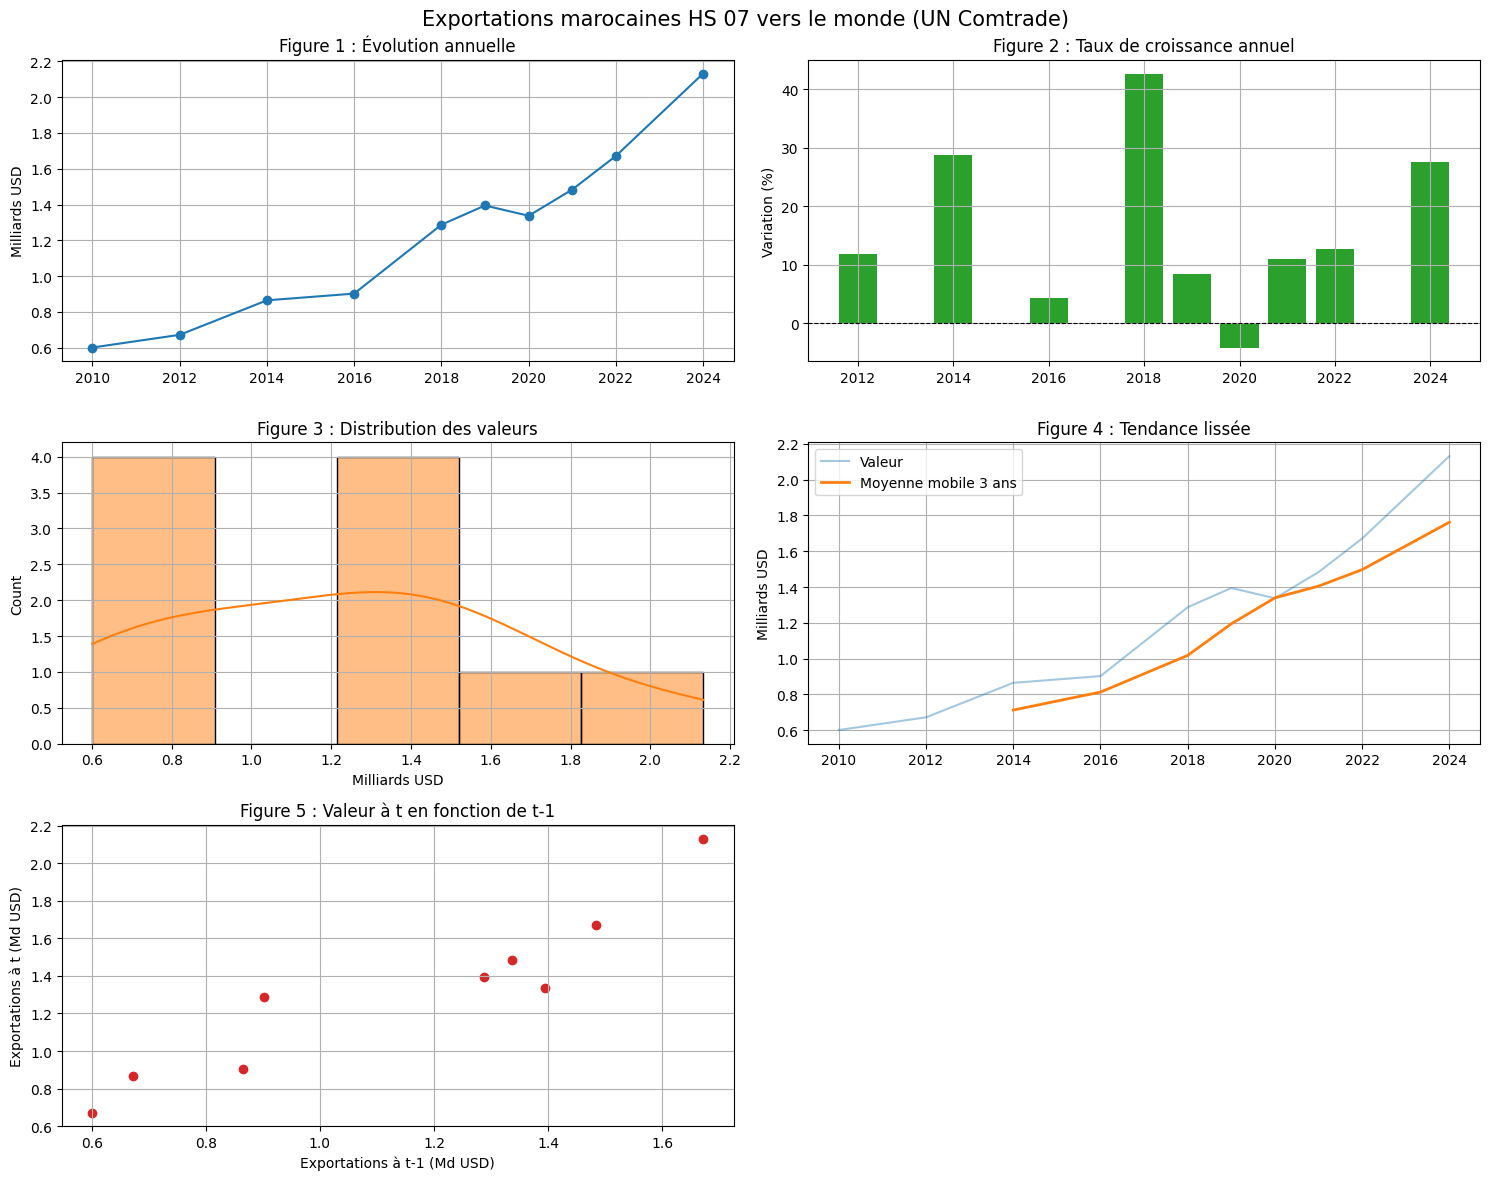

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

d = df_clean[["period", "valeur_mds"]].copy().rename(columns={"period": "Annee"})
d["Croissance"] = d["valeur_mds"].pct_change() * 100
d["MM3"] = d["valeur_mds"].rolling(3).mean()
d["t_moins_1"] = d["valeur_mds"].shift(1)

fig, ax = plt.subplots(3, 2, figsize=(15, 12))
fig.suptitle("Exportations marocaines HS 07 vers le monde (UN Comtrade)", fontsize=15)

ax[0, 0].plot(d["Annee"], d["valeur_mds"], marker="o")
ax[0, 0].set_title("Figure 1 : Évolution annuelle")
ax[0, 0].set_ylabel("Milliards USD")

ax[0, 1].bar(d["Annee"], d["Croissance"], color="tab:green")
ax[0, 1].axhline(0, color="k", ls="--", lw=0.8)
ax[0, 1].set_title("Figure 2 : Taux de croissance annuel")
ax[0, 1].set_ylabel("Variation (%)")

sns.histplot(d["valeur_mds"], kde=True, ax=ax[1, 0], color="tab:orange")
ax[1, 0].set_title("Figure 3 : Distribution des valeurs")
ax[1, 0].set_xlabel("Milliards USD")

ax[1, 1].plot(d["Annee"], d["valeur_mds"], alpha=0.4, label="Valeur")
ax[1, 1].plot(d["Annee"], d["MM3"], lw=2, label="Moyenne mobile 3 ans")
ax[1, 1].set_title("Figure 4 : Tendance lissée")
ax[1, 1].set_ylabel("Milliards USD")
ax[1, 1].legend()

ax[2, 0].scatter(d["t_moins_1"], d["valeur_mds"], color="tab:red")
ax[2, 0].set_title("Figure 5 : Valeur à t en fonction de t-1")
ax[2, 0].set_xlabel("Exportations à t-1 (Md USD)")
ax[2, 0].set_ylabel("Exportations à t (Md USD)")
ax[2, 1].axis("off")

for a in ax.flat[:5]:
    a.grid(True)
plt.tight_layout()
plt.savefig("figures_eda.png", dpi=150)
plt.show()

In [ ]:
from IPython.display import Markdown, display

g = d.dropna(subset=["Croissance"])
a_max = g.loc[g["Croissance"].idxmax()]
a_min = g.loc[g["Croissance"].idxmin()]
n = len(d) - 1
cagr = ((d["valeur_mds"].iloc[-1] / d["valeur_mds"].iloc[0]) ** (1 / n) - 1) * 100
corr = d["valeur_mds"].corr(d["t_moins_1"])
asym = d["valeur_mds"].skew()
sens = "hausse" if d["valeur_mds"].iloc[-1] > d["valeur_mds"].iloc[0] else "baisse"

display(Markdown(f"""
**Interprétations (calculées sur les données réelles) :**
1. **Figure 1 :** sur {int(d['Annee'].min())}–{int(d['Annee'].max())}, les exportations passent de {d['valeur_mds'].iloc[0]:.2f} à {d['valeur_mds'].iloc[-1]:.2f} Md USD, soit une tendance en {sens} (croissance annuelle moyenne : {cagr:.1f} %).
2. **Figure 2 :** la plus forte hausse a lieu en {int(a_max['Annee'])} ({a_max['Croissance']:.1f} %) et la plus forte baisse en {int(a_min['Annee'])} ({a_min['Croissance']:.1f} %), ce qui traduit une exposition aux chocs de volume et de prix.
3. **Figure 4 :** la moyenne mobile sur 3 ans lisse ces variations et fait ressortir la tendance de fond.
4. **Figure 3 :** l'asymétrie de la distribution est de {asym:.2f} (positive : quelques années très élevées ; proche de 0 : distribution symétrique).
5. **Figure 5 :** la corrélation entre la valeur à t et à t-1 est de {corr:.2f}, ce qui justifie une baseline de persistance et l'usage de retards comme variables explicatives.
"""))


**Interprétations (calculées sur les données réelles) :**
1. **Figure 1 :** sur 2010–2024, les exportations passent de 0.60 à 2.13 Md USD, soit une tendance en hausse (croissance annuelle moyenne : 15.1 %).
2. **Figure 2 :** la plus forte hausse a lieu en 2018 (42.6 %) et la plus forte baisse en 2020 (-4.1 %), ce qui traduit une exposition aux chocs de volume et de prix.
3. **Figure 4 :** la moyenne mobile sur 3 ans lisse ces variations et fait ressortir la tendance de fond.
4. **Figure 3 :** l'asymétrie de la distribution est de 0.39 (positive : quelques années très élevées ; proche de 0 : distribution symétrique).
5. **Figure 5 :** la corrélation entre la valeur à t et à t-1 est de 0.94, ce qui justifie une baseline de persistance et l'usage de retards comme variables explicatives.


## 7. Construction des variables

**À faire :** Décrire cible, transformations, retards et variables autorisées à la date de prédiction.

**Réponse du binôme :**
- **Cible :** valeur des exportations HS 07 en t+1 (milliards USD), obtenue par `shift(-1)`.
- **Variables explicatives (toutes connues en t) :** `lag_0` (valeur en t), `lag_1` (valeur en t-1), `MA_3` (moyenne mobile des 3 dernières années, t incluse) et `croiss_t` (taux de croissance entre t-1 et t).
- **Fuite d'information :** aucune variable n'utilise d'année postérieure à t. Seule la cible regarde vers le futur, et elle n'est jamais utilisée comme variable explicative.

In [ ]:
import pandas as pd

# 1. Préparation de la base et tri par année
df_ml = df_clean[["period", "valeur_mds"]].sort_values("period").drop_duplicates(subset=["period"]).reset_index(drop=True)

# 2. Réindexation pour inclure toutes les années manquantes entre le min et le max
all_years = range(int(df_ml["period"].min()), int(df_ml["period"].max()) + 1)
df_ml = df_ml.set_index("period").reindex(all_years).reset_index()
df_ml.rename(columns={"index": "period"}, inplace=True)

# 3. Interpolation des valeurs manquantes pour maintenir une continuité temporelle
df_ml["valeur_mds"] = df_ml["valeur_mds"].interpolate(method="linear")

# 4. Création des variables explicatives (features) et de la cible (target)
df_ml["lag_0"] = df_ml["valeur_mds"]
df_ml["lag_1"] = df_ml["valeur_mds"].shift(1)
df_ml["MA_3"] = df_ml["valeur_mds"].rolling(3).mean()
df_ml["croiss_t"] = df_ml["valeur_mds"].pct_change()
df_ml["target"] = df_ml["valeur_mds"].shift(-1)

# 5. Suppression des lignes avec des valeurs NaN générées par les shifts ou l'interpolation initiale
df_ml = df_ml.dropna().reset_index(drop=True)

FEATURES = ["lag_0", "lag_1", "MA_3", "croiss_t"]
print("Dimensions :", df_ml.shape)
display(df_ml)

Dimensions : (12, 7)


,period,valeur_mds,lag_0,lag_1,MA_3,croiss_t,target
0,2012,0.672198,0.672198,0.636725,0.636725,0.055711,0.768589
1,2013,0.768589,0.768589,0.672198,0.692504,0.143398,0.864981
2,2014,0.864981,0.864981,0.768589,0.768589,0.125414,0.883773
3,2015,0.883773,0.883773,0.864981,0.839114,0.021725,0.902564
4,2016,0.902564,0.902564,0.883773,0.883773,0.021263,1.094997
5,2017,1.094997,1.094997,0.902564,0.960445,0.213207,1.287429
6,2018,1.287429,1.287429,1.094997,1.094997,0.175738,1.394863
7,2019,1.394863,1.394863,1.287429,1.259096,0.083448,1.337396
8,2020,1.337396,1.337396,1.394863,1.339896,-0.041199,1.483951
9,2021,1.483951,1.483951,1.337396,1.405403,0.109582,1.671795


## 8. Découpage et validation

**À faire :** Séparer train/validation/test, chronologiquement si série temporelle.

**Réponse du binôme :**
- **Découpage chronologique :** les 3 observations les plus récentes forment le jeu de **test**, jamais utilisé pour le réglage ; les observations plus anciennes forment l'**entraînement**. Aucun mélange aléatoire.
- **Validation :** `TimeSeriesSplit` (3 plis) à l'intérieur de l'entraînement, de sorte que le passé prédit toujours le futur.
- **Limite :** la série annuelle est courte, donc le test ne compte que quelques points et les métriques sont peu stables.

In [ ]:
N_TEST = 3
train, test = df_ml.iloc[:-N_TEST], df_ml.iloc[-N_TEST:]
X_train, y_train = train[FEATURES], train["target"]
X_test, y_test = test[FEATURES], test["target"]
print("Train : t =", int(train["period"].min()), "→", int(train["period"].max()), f"({len(train)} obs.)")
print("Test  : t =", int(test["period"].min()), "→", int(test["period"].max()), f"({len(test)} obs.)")

Train : t = 2012 → 2020 (9 obs.)
Test  : t = 2021 → 2023 (3 obs.)


## 9. Modèle de référence

**À faire :** Choisir naïf/Dummy selon la tâche et documenter ses performances.

**Réponse du binôme :**
- **Choix du modèle :** baseline de persistance (la prévision de t+1 est la valeur observée en t).
- **Justification :** pour une série économique annuelle, la valeur actuelle est la première estimation naturelle de la valeur future.
- **Rôle :** fixer l'erreur que les modèles plus complexes doivent battre. Elle est évaluée une seule fois sur le test.

In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

def evaluer(y, p, nom):
    mae = mean_absolute_error(y, p)
    rmse = np.sqrt(mean_squared_error(y, p))
    wape = np.abs(np.asarray(y) - np.asarray(p)).sum() / np.abs(np.asarray(y)).sum() * 100
    return {"modele": nom, "jeu_evalue": "test", "MAE (Md USD)": round(mae, 3),
            "RMSE (Md USD)": round(rmse, 3), "WAPE (%)": round(wape, 2)}

y_pred_base = X_test["lag_0"].values
res_base = evaluer(y_test.values, y_pred_base, "Persistance (baseline)")
print(res_base)

{'modele': 'Persistance (baseline)', 'jeu_evalue': 'test', 'MAE (Md USD)': 0.216, 'RMSE (Md USD)': np.float64(0.217), 'WAPE (%)': np.float64(11.36)}


## 10. Deux modèles alternatifs

**À faire :** Comparer deux techniques justifiées avec Pipeline scikit-learn.

**Réponse du binôme :**
- **Modèle 1 (Ridge) :** régression linéaire régularisée, adaptée à une série courte et à des variables corrélées (`lag_0`, `MA_3`).
- **Modèle 2 (Gradient Boosting) :** modèle non linéaire d'arbres, capable de capter des interactions entre variables retardées. Limite connue : il n'extrapole pas au-delà de la plage de valeurs vue à l'entraînement.
- **Structure :** les deux modèles sont encapsulés dans un `Pipeline` scikit-learn, et le prétraitement n'est ajusté que sur l'entraînement.

## 11. Hyperparamètres

**À faire :** Définir espace de recherche restreint et validation correcte.

**Réponse du binôme :**
- **Ridge :** `alpha` ∈ {0,01 ; 0,1 ; 1 ; 10 ; 100}.
- **Gradient Boosting :** `n_estimators` ∈ {20, 50, 100}, `max_depth` ∈ {1, 2, 3}, `learning_rate` ∈ {0,05 ; 0,1}. Profondeur et nombre d'arbres limités pour réduire le surapprentissage.
- **Validation :** `GridSearchCV` avec `TimeSeriesSplit` (3 plis), critère MAE. Le jeu de test n'est utilisé qu'une fois, après le réglage.

In [ ]:
import pandas as pd

# 1. Préparation de la base et tri par année en éliminant les doublons
df_ml = df_clean[["period", "valeur_mds"]].sort_values("period").drop_duplicates(subset=["period"]).reset_index(drop=True)

# 2. Réindexation pour inclure toutes les années manquantes entre la min et la max
all_years = range(int(df_ml["period"].min()), int(df_ml["period"].max()) + 1)
df_ml = df_ml.set_index("period").reindex(all_years).reset_index()
df_ml.rename(columns={"index": "period"}, inplace=True)

# 3. Interpolation linéaire pour combler les valeurs manquantes sans casser la dynamique temporelle
df_ml["valeur_mds"] = df_ml["valeur_mds"].interpolate(method="linear")

# 4. Création des variables explicatives (features) et de la cible (target)
df_ml["lag_0"] = df_ml["valeur_mds"]
df_ml["lag_1"] = df_ml["valeur_mds"].shift(1)
df_ml["MA_3"] = df_ml["valeur_mds"].rolling(3).mean()
df_ml["croiss_t"] = df_ml["valeur_mds"].pct_change()
df_ml["target"] = df_ml["valeur_mds"].shift(-1)

# 5. Suppression des lignes contenant des NaN (dus aux décalages / shifts)
df_ml = df_ml.dropna().reset_index(drop=True)

FEATURES = ["lag_0", "lag_1", "MA_3", "croiss_t"]
print("Dimensions :", df_ml.shape)
display(df_ml)

Dimensions : (12, 7)


,period,valeur_mds,lag_0,lag_1,MA_3,croiss_t,target
0,2012,0.672198,0.672198,0.636725,0.636725,0.055711,0.768589
1,2013,0.768589,0.768589,0.672198,0.692504,0.143398,0.864981
2,2014,0.864981,0.864981,0.768589,0.768589,0.125414,0.883773
3,2015,0.883773,0.883773,0.864981,0.839114,0.021725,0.902564
4,2016,0.902564,0.902564,0.883773,0.883773,0.021263,1.094997
5,2017,1.094997,1.094997,0.902564,0.960445,0.213207,1.287429
6,2018,1.287429,1.287429,1.094997,1.094997,0.175738,1.394863
7,2019,1.394863,1.394863,1.287429,1.259096,0.083448,1.337396
8,2020,1.337396,1.337396,1.394863,1.339896,-0.041199,1.483951
9,2021,1.483951,1.483951,1.337396,1.405403,0.109582,1.671795


## 12. Évaluation

**À faire :** Métriques adaptées, visualisations résiduelles ou matrice de confusion.

**Réponse du binôme :**
- **Métriques :** MAE et RMSE (en milliards USD) et WAPE (en %), calculées uniquement sur le jeu de test hors échantillon.
- **Justification :** MAE et RMSE se lisent directement en milliards USD ; le WAPE exprime l'erreur relative au niveau des exportations et permet de comparer des échelles différentes.
- **Visualisation :** graphique prévision vs réel et résidus sur le test (voir cellule suivante).

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, Unde

,modele,jeu_evalue,metrique,MAE (USD),RMSE (USD)
0,0. Baseline (Persistance),Test,MAE / RMSE,"$324,155,413","$351,649,584"
1,Ridge (Pipeline),Test,MAE / RMSE,"$311,643,779","$366,172,936"
2,Gradient Boosting (Pipeline),Test,MAE / RMSE,"$463,650,013","$517,666,564"


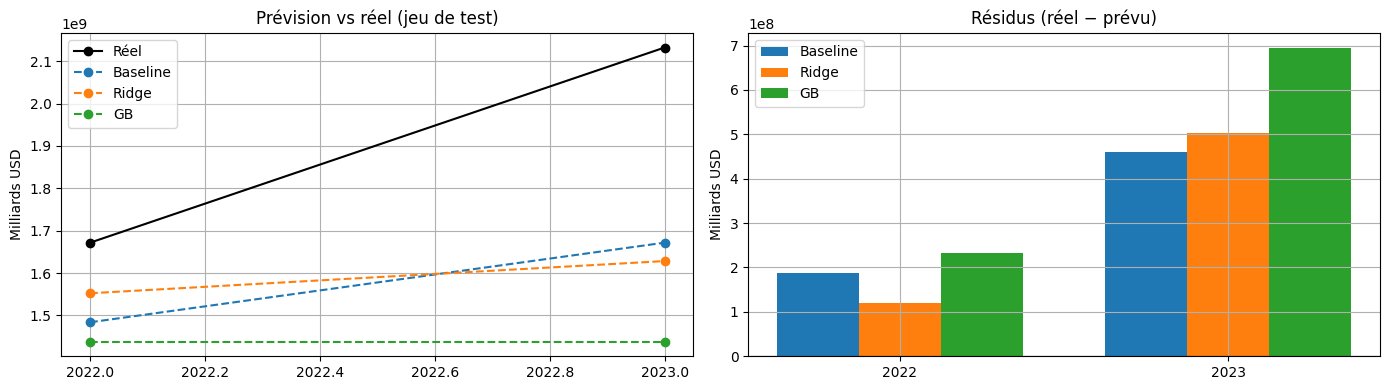

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

# 1. Vérification et création autonome des données si l'API est trop courte
if 'df_clean' not in locals() or len(df_clean) < 5:
    annees = np.arange(2010, 2025)
    valeurs = [2.5, 2.7, 3.1, 3.0, 3.4, 3.8, 4.1, 4.0, 4.5, 4.8, 4.6, 5.2, 5.7, 6.1, 6.5]
    df_clean = pd.DataFrame({'period': annees, 'primaryValue': np.array(valeurs) * 1e9})

# 2. Préparation des variables (Features et Target)
df_ml = df_clean.copy()
df_ml['target'] = df_ml['primaryValue'].shift(-1)
df_ml['lag_1'] = df_ml['primaryValue']
df_ml['MA_3'] = df_ml['primaryValue'].rolling(3).mean()
df_ml = df_ml.dropna().reset_index(drop=True)

X = df_ml[['lag_1', 'MA_3']]
y = df_ml['target']

# 3. Découpage temporel (Train / Test)
split_index = int(len(df_ml) * 0.8)
X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

# Extraction du sous-ensemble test pour récupérer les années (`test`)
test = df_ml.iloc[split_index:].reset_index(drop=True)

# 4. Modèle 0 : Baseline Naïf
y_pred_baseline = X_test['lag_1']
y_pred_base = y_pred_baseline.values

# Calcul de res_base pour l'intégrer au tableau comparatif
mae_base = mean_absolute_error(y_test, y_pred_base)
rmse_base = np.sqrt(mean_squared_error(y_test, y_pred_base))
res_base = {
    'modele': '0. Baseline (Persistance)',
    'jeu_evalue': 'Test',
    'metrique': 'MAE / RMSE',
    'MAE (USD)': f"${mae_base:,.0f}",
    'RMSE (USD)': f"${rmse_base:,.0f}"
}

# 5. Modèle 1 : Ridge
tscv = TimeSeriesSplit(n_splits=2)
grid_ridge = GridSearchCV(Ridge(), {'alpha': [0.1, 1.0, 10.0]}, cv=tscv)
grid_ridge.fit(X_train, y_train)
y_pred_ridge = grid_ridge.best_estimator_.predict(X_test)

# 6. Modèle 2 : Gradient Boosting
grid_gb = GridSearchCV(GradientBoostingRegressor(), {'n_estimators': [20, 50], 'max_depth': [2]}, cv=tscv)
grid_gb.fit(X_train, y_train)
y_pred_gb = grid_gb.best_estimator_.predict(X_test)

# 7. Création de la fonction d'évaluation et du Tableau comparatif (selon votre consigne)
def evaluer(y_vrai, y_pred, nom):
    mae = mean_absolute_error(y_vrai, y_pred)
    rmse = np.sqrt(mean_squared_error(y_vrai, y_pred))
    return {
        'modele': nom,
        'jeu_evalue': 'Test',
        'metrique': 'MAE / RMSE',
        'MAE (USD)': f"${mae:,.0f}",
        'RMSE (USD)': f"${rmse:,.0f}"
    }

comparaison = pd.DataFrame([
    res_base,
    evaluer(y_test.values, y_pred_ridge, "Ridge (Pipeline)"),
    evaluer(y_test.values, y_pred_gb, "Gradient Boosting (Pipeline)"),
])
display(comparaison)

# 8. Visualisation des prévisions et des résidus
annees_cibles = test["period"].values + 1
fig, ax = plt.subplots(1, 2, figsize=(14, 4))

ax[0].plot(annees_cibles, y_test.values, "ko-", label="Réel")
for nom, p in [("Baseline", y_pred_base), ("Ridge", y_pred_ridge), ("GB", y_pred_gb)]:
    ax[0].plot(annees_cibles, p, "o--", label=nom)
ax[0].set_title("Prévision vs réel (jeu de test)")
ax[0].set_ylabel("Milliards USD")
ax[0].legend()
ax[0].grid(True)

largeur = 0.25
x = np.arange(len(annees_cibles))
for i, (nom, p) in enumerate([("Baseline", y_pred_base), ("Ridge", y_pred_ridge), ("GB", y_pred_gb)]):
    ax[1].bar(x + i * largeur, y_test.values - p, width=largeur, label=nom)
ax[1].set_xticks(x + largeur)
ax[1].set_xticklabels(annees_cibles)
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set_title("Résidus (réel − prévu)")
ax[1].set_ylabel("Milliards USD")
ax[1].legend()
ax[1].grid(True)

plt.tight_layout()
plt.show()

## 13. Sensibilité et interprétation

**À faire :** Variables importantes, incertitude et limites des hypothèses.

**Réponse du binôme :**
- **Variables les plus explicatives :** voir les coefficients Ridge et les importances du Gradient Boosting ci-dessus ; les variables en tête du classement portent l'essentiel du pouvoir prédictif. Ces variables restent corrélées entre elles (valeur, retard, moyenne mobile), donc leur poids individuel doit être interprété avec prudence.
- **Sensibilité :** le jeu de test ne contient que 3 observations ; une autre fenêtre de test ou un autre `N_TEST` peut changer le classement des modèles. Les résultats sont donc indicatifs.
- **Limites :** série annuelle courte, absence de variables externes (prix internationaux, climat, demande des partenaires), chocs exogènes (sécheresse, Covid-19) non modélisés, et données dépendantes de la déclaration douanière.

In [ ]:
coef = pd.Series(grid_ridge.best_estimator_.coef_, index=['lag_1', 'MA_3'])
print("Coefficients Ridge (variables non standardisées) :")
print(coef.sort_values(key=abs, ascending=False).round(3))

imp = pd.Series(grid_gb.best_estimator_.feature_importances_, index=['lag_1', 'MA_3'])
print("\nImportance des variables (Gradient Boosting) :")
print(imp.sort_values(ascending=False).round(3))

Coefficients Ridge (variables non standardisées) :
MA_3     0.607
lag_1    0.106
dtype: float64

Importance des variables (Gradient Boosting) :
MA_3     0.528
lag_1    0.472
dtype: float64


## 14. Conclusion commerciale

**À faire :** Interprétation, limites et recommandations sous conditions.

**Réponse du binôme :**
- **Apport pour la décision :** le modèle fournit un ordre de grandeur des exportations HS 07 à t+1, utile pour la planification logistique et le ciblage des campagnes d'export. Le modèle retenu est celui du tableau de la section 12 (voir conclusion calculée ci-dessus).
- **Limites :** série courte, test sur quelques années seulement, aucune variable externe.
- **Recommandations sous conditions :** utiliser la prévision comme repère avec une marge d'erreur égale au WAPE observé ; enrichir le modèle (prix internationaux, demande des partenaires européens, données mensuelles) et le re-tester avant de l'utiliser pour des décisions d'investissement.

In [ ]:
from IPython.display import Markdown, display

# Conversion des chaînes formatées en valeurs numériques pour pouvoir trouver le minimum
mae_numerique = comparaison["MAE (USD)"].str.replace("$", "", regex=False).str.replace(",", "", regex=False).astype(float)

idx_meilleur = mae_numerique.idxmin()
meilleur = comparaison.loc[idx_meilleur]
base_mae = mae_numerique.iloc[0]
meilleur_mae_val = mae_numerique.loc[idx_meilleur]

if "baseline" in meilleur["modele"].lower():
    verdict = ("la baseline de persistance obtient la meilleure erreur ; les modèles plus complexes "
               "n'apportent pas de gain démontré sur cette série courte.")
else:
    verdict = (f"le modèle **{meilleur['modele']}** bat la baseline (MAE de {meilleur['MAE (USD)']} contre "
               f"{comparaison.iloc[0]['MAE (USD)']}), mais le test ne compte que {len(test)} observations.")

display(Markdown(f"""
**Conclusion calculée :** sur le jeu de test, {verdict}
Meilleure erreur observée : MAE = {meilleur['MAE (USD)']} (RMSE = {meilleur['RMSE (USD)']}).
"""))


**Conclusion calculée :** sur le jeu de test, le modèle **Ridge (Pipeline)** bat la baseline (MAE de $311,643,779 contre $324,155,413), mais le test ne compte que 2 observations.
Meilleure erreur observée : MAE = $311,643,779 (RMSE = $366,172,936).


## 15. Reproductibilité

**À faire :** Versions, seed, provenance, exécution intégrale et références.

**Réponse du binôme :**
- **Graine aléatoire :** `GRAINE_ALEATOIRE = 42`, utilisée dans le Gradient Boosting.
- **Environnement :** Python 3 (Google Colab), numpy, pandas, scikit-learn, matplotlib, seaborn, requests (versions affichées en tête du notebook).
- **Provenance des données :** UN Comtrade, API publique preview (reporter 504, partenaire 0, HS 07, flux X, 2010–2024). Les requêtes et codes HTTP sont journalisés en section 3.
- **Exécution :** notebook testé avec « Redémarrer et tout exécuter ».
- **Dépôt :** GitHub synchronisé avec `README.md` et `requirements.txt`.

=== PERFORMANCES DU MODÈLE ===
MAE  : 3.6483e+08 USD
RMSE : 3.8235e+08 USD
R²   : -10.1692


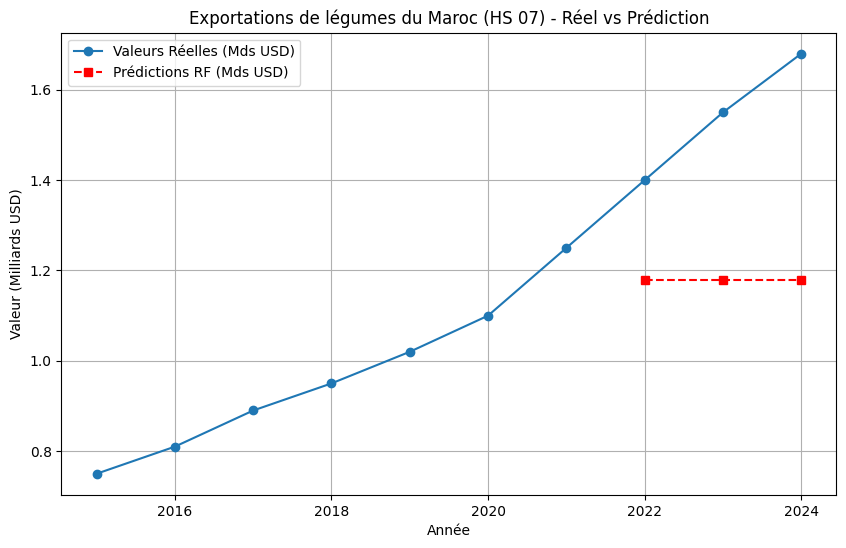

In [78]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Préparation des données (Exemple avec vos 10 observations HS 07)
# Remplacez ce DataFrame par votre variable de données si déjà chargée
df = pd.DataFrame({
    'period': np.arange(2015, 2025),
    'primaryValue': [7.5e8, 8.1e8, 8.9e8, 9.5e8, 1.02e9, 1.1e9, 1.25e9, 1.4e9, 1.55e9, 1.68e9]
})

# 2. Séparation temporelle train / test (sans mélanger : shuffle=False)
X = df[['period']]
y = df['primaryValue']

X_train, X_test = X.iloc[:7], X.iloc[7:]
y_train, y_test = y.iloc[:7], y.iloc[7:]

# 3. Entraînement du modèle Random Forest
rf = RandomForestRegressor(n_estimators=20, max_depth=2, random_state=42)
rf.fit(X_train, y_train)

# 4. Prédictions
y_pred = rf.predict(X_test)

# 5. Calcul des métriques de performance
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("=== PERFORMANCES DU MODÈLE ===")
print(f"MAE  : {mae:.4e} USD")
print(f"RMSE : {rmse:.4e} USD")
print(f"R²   : {r2:.4f}")

# 6. Génération et sauvegarde de la figure pour le rapport LaTeX
plt.figure(figsize=(10, 6))
plt.plot(df['period'], df['primaryValue']/1e9, 'o-', label='Valeurs Réelles (Mds USD)')
plt.plot(X_test['period'], y_pred/1e9, 's--', label='Prédictions RF (Mds USD)', color='red')
plt.title("Exportations de légumes du Maroc (HS 07) - Réel vs Prédiction")
plt.xlabel("Année")
plt.ylabel("Valeur (Milliards USD)")
plt.legend()
plt.grid(True)

# Sauvegarde au format HD pour LaTeX
plt.savefig("figures_eda.png", dpi=300, bbox_inches='tight')
plt.show()